# 00.04 — α + target + TD error

<div><span style="display:inline-block;background:#ECA82C;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">Q</span><span style="display:inline-block;background:#22A06B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TARGET</span><span style="display:inline-block;background:#C026D3;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TD ERROR</span><span style="display:inline-block;background:#E45756;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ALPHA</span></div>

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo=Path.cwd()
if repo.name=="notebooks": repo=repo.parent
sys.path.insert(0,str(repo))
from lineworld import LineWorld
from visuals import *
legend()

<div style="border-left:10px solid #22A06B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#22A06B">TARGET</div><div style="font-size:21px;font-weight:800;margin-top:4px">Target = r + γ·future</div><div style="font-size:15px;line-height:1.55;margin-top:8px">For state 3→RIGHT: reward=-.02, γ=.95, future=1.00, therefore target=.93.</div></div>

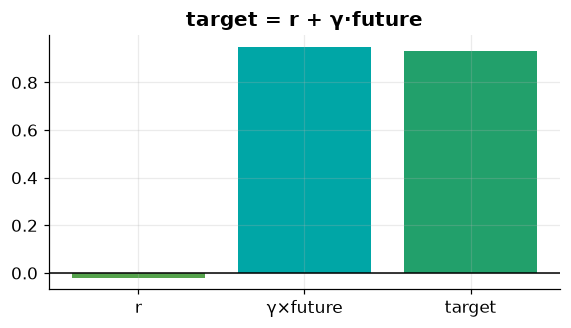

0.9299999999999999


In [2]:
reward=-.02; gamma=.95; future=1.0; target=reward+gamma*future
plt.figure(figsize=(6,3)); plt.bar(["r","γ×future","target"],[reward,gamma*future,target],color=[COLORS["REWARD"],COLORS["GAMMA"],COLORS["TARGET"]]); plt.axhline(0,color="black",lw=1); plt.title("target = r + γ·future"); plt.show()
print(target)

<div style="border-left:10px solid #C026D3;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#C026D3">TD ERROR</div><div style="font-size:21px;font-weight:800;margin-top:4px">TD error = target − old Q</div><div style="font-size:15px;line-height:1.55;margin-top:8px">How far the new one-step target is from the current estimate. This is the correction signal.</div></div>

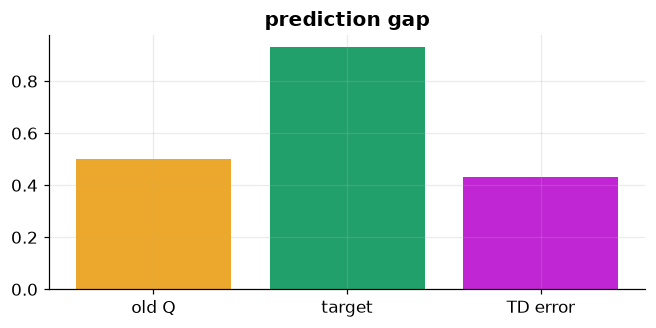

0.42999999999999994


In [3]:
old_q=.50; td=target-old_q
plt.figure(figsize=(7,3)); plt.bar(["old Q","target","TD error"],[old_q,target,td],color=[COLORS["Q"],COLORS["TARGET"],COLORS["TD ERROR"]]); plt.title("prediction gap") ; plt.show()
print(td)

<div style="border-left:10px solid #E45756;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#E45756">ALPHA</div><div style="font-size:21px;font-weight:800;margin-top:4px">α = learning rate</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Alpha scales the correction. α=.2 means move 20% of the gap toward the target. It is not exploration.</div></div>

0.5 + 0.2 × (0.9299999999999999 - 0.5) = 0.586


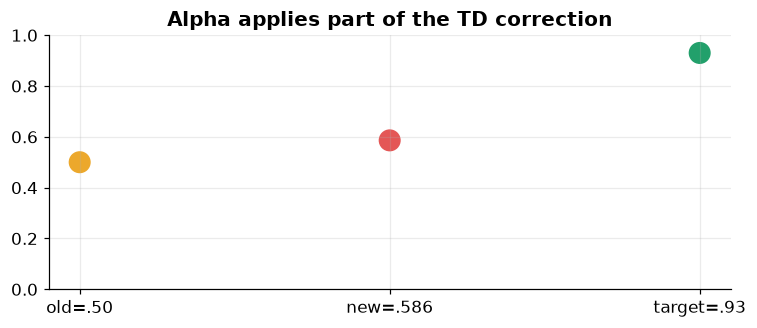

In [4]:
alpha=.2; new_q=old_q+alpha*(target-old_q)
print(f"{old_q} + {alpha} × ({target} - {old_q}) = {new_q}")
plt.figure(figsize=(8,3)); plt.scatter([0,1,2],[old_q,new_q,target],s=180,color=[COLORS["Q"],COLORS["ALPHA"],COLORS["TARGET"]]); plt.xticks([0,1,2],["old=.50","new=.586","target=.93"]); plt.ylim(0,1); plt.title("Alpha applies part of the TD correction") ; plt.show()

You were close: it is **not** `0.50 × 0.20`. It is `0.20 × (0.93 − 0.50)`. So correction=.086 and new Q=.586.

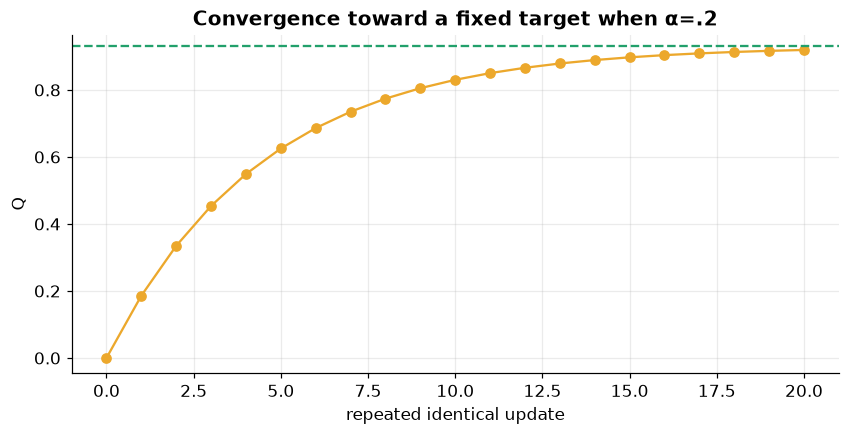

In [5]:
target=.93; alpha=.2; q=0.; hist=[q]
for _ in range(20): q=q+alpha*(target-q); hist.append(q)
plt.figure(figsize=(9,4)); plt.plot(hist,marker="o",color=COLORS["Q"]); plt.axhline(target,linestyle="--",color=COLORS["TARGET"]); plt.xlabel("repeated identical update"); plt.ylabel("Q"); plt.title("Convergence toward a fixed target when α=.2"); plt.show()

### PID analogy
Alpha is **loosely proportional-gain-like** because it scales an error signal, but Q-learning is not PID: there is no integral or derivative term here. Think “step size / learning rate” rather than PID controller.